# 04 — The amortised posterior: training record and recovery of (α, β) (System I, N3)

The old notebook 04 trained the posterior (10 000 simulations, pre-fix simulator, 29 summaries). Under the N3 re-run the training lives elsewhere: the **naive** posterior (nominal inlet assumed, S1 features) in notebook 31 and the **production** posterior
(measured inlet temperatures as inputs, S1m features, 20 000 simulations × 5 seeds, ensemble) in notebook 36. This notebook **retrains nothing**; it (1) shows the training record — the budget study's SBC / TARP / coverage tables — read from the stored metrics, and (2) shows the recovery of (α, β) on the evaluation windows.

**Rules (fixed before running; runbook §2f row g-04).** Recovery: production on **D1** (measured inlet) and naive on **D0** (nominal inlet), Sc1–Sc5 and Sc7, 50 windows per scenario, 1,000 draws each; per scenario the mean and bias of α̂ and β̂, the mean posterior sd and the 90% coverage; a per-window figure.
**Checks:** finite; 50 windows per scenario; β 90% coverage ≥ 0.80 in Sc1–Sc4 for production on D1 and for naive on D0 (α coverage is reported, not gated: Sc5 saturates). Sc7 carries a +2 K sensor drift the posteriors do not model (a misspecified scenario by design). No decision rule.


In [1]:
import os, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", f"run from notebooks/system_I (cwd {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
os.environ["CSTR_SENSOR_MODEL"] = "N3"
import importlib, ws_eval, ws_metrics, ws_phase3, ws_phase3_eval
for _m in (ws_eval, ws_metrics, ws_phase3, ws_phase3_eval):
    importlib.reload(_m)
E = ws_phase3_eval; R = ROOT / "results"; FIGS = ROOT / "figures"; FIGS.mkdir(exist_ok=True); T0 = time.time()


## 1. Training record (read from the stored metrics; nothing recomputed)

In [2]:
cols = ["budget", "ks_p_a_interior", "ks_p_b_interior", "tarp_ks_p", "cov90_a", "cov90_b", "sd_a", "sd_b", "accuracy"]
parts = []
for nm, f in (("naive (nb31: nominal inlet, S1)", "31_N3_metrics.csv"), ("production (nb36: measured inlet, S1m)", "36_N3_metrics.csv")):
    d = pd.read_csv(R / f); e = d[d.member == "ensemble"][cols].copy(); e.insert(0, "posterior", nm); parts.append(e)
rec = pd.concat(parts, ignore_index=True); display(rec.round(3)); rec.to_csv(R / "04_N3_training_record.csv", index=False)
import json
for nm, f in (("naive", "31_N3_production.json"), ("production", "36_N3_production.json")):
    j = json.loads((R / f).read_text()); print(nm, "-> deployed: budget", j["production_budget"], "| ensemble", j["use_ensemble"], "| summary set", j["summary_set"], "| members", len(j["members"]))


,posterior,budget,ks_p_a_interior,ks_p_b_interior,tarp_ks_p,cov90_a,cov90_b,sd_a,sd_b,accuracy
0,"naive (nb31: nominal inlet, S1)",5000,0.861,0.040,0.551,0.902,0.913,0.036,0.022,0.837
1,"naive (nb31: nominal inlet, S1)",10000,0.476,0.695,0.710,0.902,0.912,0.036,0.021,0.827
2,"naive (nb31: nominal inlet, S1)",20000,0.486,0.313,0.710,0.906,0.900,0.035,0.019,0.880
3,"naive (nb31: nominal inlet, S1)",40000,0.879,0.080,0.762,0.895,0.905,0.033,0.019,0.843
4,"naive (nb31: nominal inlet, S1)",80000,0.636,0.813,0.452,0.907,0.903,0.034,0.019,0.877
5,"naive (nb31: nominal inlet, S1)",160000,0.216,0.188,0.500,0.899,0.900,0.033,0.018,0.857
6,"production (nb36: measured inlet, S1m)",5000,0.088,0.008,0.710,0.903,0.901,0.037,0.046,0.787
7,"production (nb36: measured inlet, S1m)",10000,0.554,0.001,0.363,0.921,0.896,0.037,0.044,0.793
8,"production (nb36: measured inlet, S1m)",20000,0.063,0.030,0.710,0.919,0.905,0.036,0.043,0.803
9,"production (nb36: measured inlet, S1m)",40000,0.063,0.275,0.657,0.920,0.906,0.036,0.042,0.810


naive -> deployed: budget 40000 | ensemble True | summary set S1_base_est | members 5
production -> deployed: budget 20000 | ensemble True | summary set S1m_measured_inlet | members 5


## 2. Recovery on the evaluation windows

In [3]:
s_p, d1, leak_p = E.draws("prod", "D1", 1000, seed=41)
s_n, d0, leak_n = E.draws("naive", "D0", 1000, seed=42)
for s_, d_, nm in ((s_p, d1, "production on D1"), (s_n, d0, "naive on D0")):
    assert np.isfinite(s_).all() and all((d_["scenario_id"] == sc).sum() == 50 for sc in E.SCN), nm
print(f"prior leakage: production {leak_p.mean():.4f}, naive {leak_n.mean():.4f}")
tp = E.per_scenario(s_p, d1, extra=False); tn = E.per_scenario(s_n, d0, extra=False)
show = ["scenario", "alpha_true", "beta_true", "alpha_mean", "alpha_bias", "alpha_sd", "alpha_cov90", "beta_mean", "beta_bias", "beta_sd", "beta_cov90", "class_acc"]
print("Production posterior on D1 (measured inlet)"); display(tp[show].round(3))
print("Naive posterior on D0 (nominal inlet; its valid domain)"); display(tn[show].round(3))
assert (tp[tp.scenario.isin(["Sc1", "Sc2", "Sc3", "Sc4"])].beta_cov90 >= 0.80).all() and (tn[tn.scenario.isin(["Sc1", "Sc2", "Sc3", "Sc4"])].beta_cov90 >= 0.80).all(), "beta coverage check failed"
print("check passed: beta coverage >= 0.80 in Sc1-Sc4 (production on D1, naive on D0)")
tp.assign(posterior="production on D1").to_csv(R / "04_N3_recovery_production_D1.csv", index=False); tn.assign(posterior="naive on D0").to_csv(R / "04_N3_recovery_naive_D0.csv", index=False)


prior leakage: production 0.0150, naive 0.0006
Production posterior on D1 (measured inlet)


,scenario,alpha_true,beta_true,alpha_mean,alpha_bias,alpha_sd,alpha_cov90,beta_mean,beta_bias,beta_sd,beta_cov90,class_acc
0,Sc1,1.00,1.00,1.016,0.016,0.055,0.90,1.000,0.000,0.046,0.94,0.98
1,Sc2,1.00,0.85,1.015,0.015,0.056,0.90,0.857,0.007,0.046,0.92,0.84
2,Sc3,0.70,1.00,0.702,0.002,0.030,0.96,0.994,-0.006,0.042,0.86,1.00
3,Sc4,0.85,0.85,0.854,0.004,0.043,0.92,0.849,-0.001,0.044,0.96,0.90
4,Sc5,1.00,0.50,1.016,0.016,0.058,0.88,0.502,0.002,0.042,0.96,1.00
5,Sc7,1.00,0.85,0.901,-0.099,0.071,0.64,0.456,-0.394,0.029,0.00,0.52


Naive posterior on D0 (nominal inlet; its valid domain)


,scenario,alpha_true,beta_true,alpha_mean,alpha_bias,alpha_sd,alpha_cov90,beta_mean,beta_bias,beta_sd,beta_cov90,class_acc
0,Sc1,1.00,1.00,1.018,0.018,0.054,0.92,1.001,0.001,0.015,0.94,1.00
1,Sc2,1.00,0.85,1.006,0.006,0.053,0.90,0.848,-0.002,0.014,0.94,0.98
2,Sc3,0.70,1.00,0.700,-0.000,0.026,0.86,1.002,0.002,0.015,0.94,1.00
3,Sc4,0.85,0.85,0.849,-0.001,0.039,0.90,0.850,-0.000,0.014,0.88,0.94
4,Sc5,1.00,0.50,1.010,0.010,0.057,0.94,0.501,0.001,0.024,0.90,0.98
5,Sc7,1.00,0.85,0.872,-0.128,0.062,0.36,0.467,-0.383,0.020,0.00,0.30


check passed: beta coverage >= 0.80 in Sc1-Sc4 (production on D1, naive on D0)


## 3. Figure: posterior mean and 90% interval per window

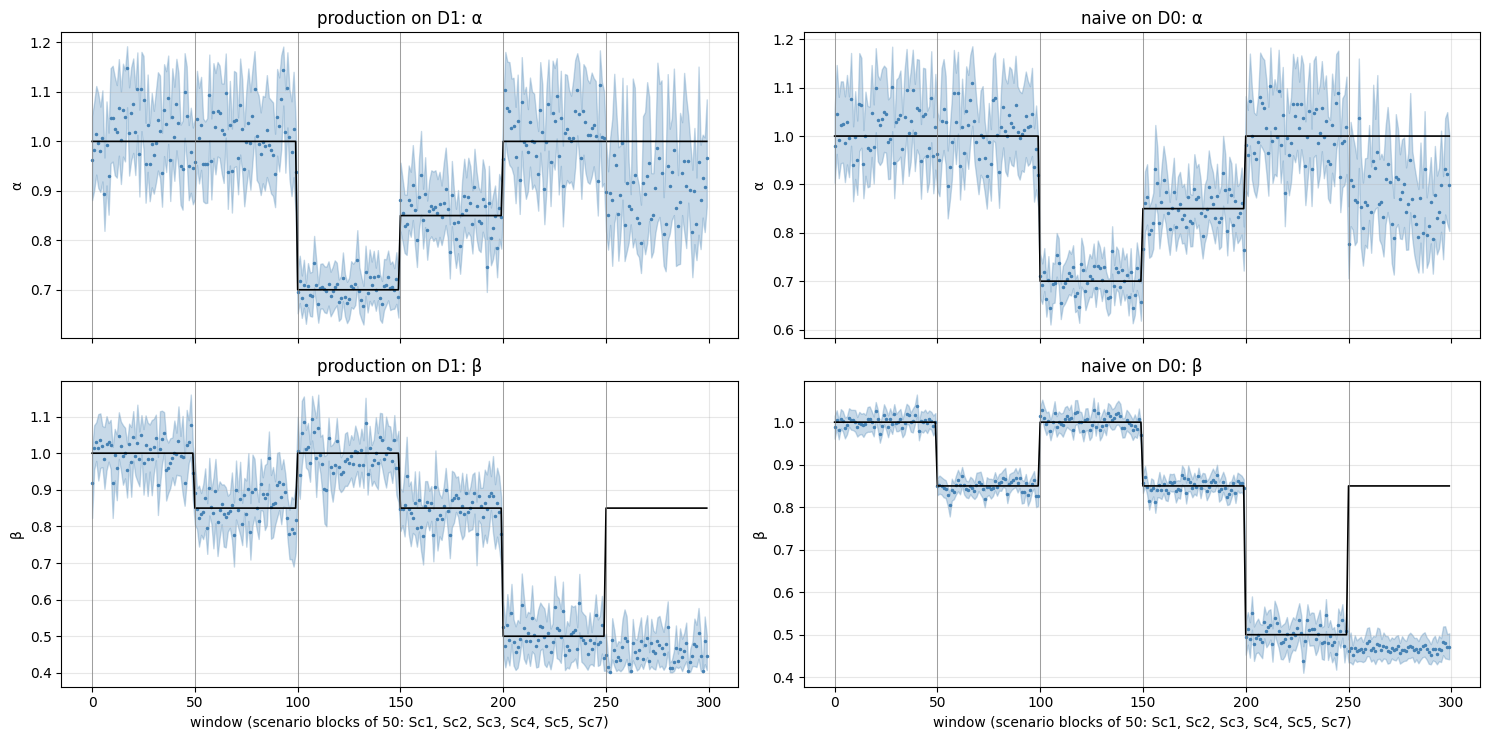

notebook wall time 0.2 min


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 7.5), sharex="col")
for col, (s_, d_, ttl) in enumerate(((s_p, d1, "production on D1"), (s_n, d0, "naive on D0"))):
    th = d_["theta"][:, 2:]; mean = s_.mean(1); lo = np.quantile(s_, .05, axis=1); hi = np.quantile(s_, .95, axis=1); x = np.arange(len(th))
    for row, (j, nm) in enumerate(((0, "α"), (1, "β"))):
        ax = axes[row, col]; ax.fill_between(x, lo[:, j], hi[:, j], alpha=.3, color="steelblue"); ax.plot(x, mean[:, j], ".", ms=3, color="steelblue"); ax.plot(x, th[:, j], "k-", lw=1.2)
        ax.set_ylabel(nm); ax.set_title(f"{ttl}: {nm}"); ax.grid(alpha=.3)
        for b in range(0, len(th), 50): ax.axvline(b, color="grey", lw=.5)
    axes[1, col].set_xlabel("window (scenario blocks of 50: Sc1, Sc2, Sc3, Sc4, Sc5, Sc7)")
fig.tight_layout(); fig.savefig(FIGS / "04_N3_recovery.png", dpi=150); plt.show()
print(f"notebook wall time {(time.time() - T0) / 60:.1f} min")


## 5. Interpretation

**Training record.** Both posteriors are calibrated at every budget in the coverage sense (90% coverage 0.90–0.92 for α and β throughout), and the TARP joint-coverage test is passed (KS p 0.36–0.76). The marginal SBC on the interior subset is more demanding: the naive posterior passes at every budget (KS p 0.04–0.88 for β, 0.22–0.88 for α); the production posterior passes at the deployed
budget of 20 000 (α 0.063, β 0.030, TARP 0.71) but not at every budget (β 0.008 at 5k and 0.001 at 10k), which is why the deployed object is the 5-seed ensemble and why notebook 36 carries a documented acceptance exception. The cost of the realistic inlet is in the width, not the calibration: the posterior sd of β is 0.041–0.046 (production) against 0.018–0.022 (naive); α is unchanged
(0.033–0.037). The budget barely matters for the width above 20k, which is why 20k was chosen.

**Recovery.** The production posterior on D1 recovers (α, β) without bias in Sc1–Sc5: |bias| ≤ 0.016 for α and ≤ 0.007 for β, β coverage 0.86–0.96 and α coverage 0.88–0.96. The naive posterior on D0, its valid domain, is equally unbiased but three times sharper in β (sd 0.014–0.024; coverage 0.88–0.94), because it assumes an inlet that is
exactly nominal there. **Sc7 is the misspecified scenario for both** (a +2 K T-sensor drift that neither models): β̂ is biased by −0.394 (production) and −0.383 (naive), the β coverage is 0.00 and α is biased by −0.10 to −0.13; the remedy is in notebooks 09 (drift-aware posterior), 11b (detector) and 38 (deployment combination).
The two recoveries are on different data (D1 against D0), so their widths are not a like-for-like comparison of methods; the like-for-like statement is the cost of an unknown-within-±2 K inlet, ×2–3 in the β sd.

**Ledger.** Supports: calibrated, unbiased recovery in the well-specified scenarios with the production posterior; the budget study. Documents: the ×2–3 price of the inlet uncertainty in β; the single-seed SBC failures; Sc7.